In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

df = pd.read_csv("AirPassengers.csv")

df["Month"] = pd.to_datetime(df["Month"])

passengers = df["#Passengers"].values.reshape(-1, 1)

scaler = MinMaxScaler()
passengers_scaled = scaler.fit_transform(passengers)

seq_length = 12

X = []
y = []

for i in range(len(passengers_scaled) - seq_length):
    X.append(passengers_scaled[i:i + seq_length])
    y.append(passengers_scaled[i + seq_length])

X = np.array(X)
y = np.array(y)

train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Input shape:", X_train.shape)
print("Output shape:", y_train.shape)

Training samples: 105
Testing samples: 27
Input shape: torch.Size([105, 12, 1])
Output shape: torch.Size([105, 1])


In [ ]:
class LSTMModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=64,
            num_layers=2,
            batch_first=True
        )

        self.fc = nn.Linear(64, 1)

    def forward(self, x):

        output, _ = self.lstm(x)

        output = output[:, -1, :]

        output = self.fc(output)

        return output


model = LSTMModel()

print(model)

In [ ]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 100

train_losses = []

for epoch in range(epochs):

    model.train()

    optimizer.zero_grad()

    predictions = model(X_train)

    loss = criterion(predictions, y_train)

    loss.backward()

    optimizer.step()

    train_losses.append(loss.item())

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}] "
            f"Loss: {loss.item():.6f}"
        )

Epoch [10/100] Loss: 0.004914
Epoch [20/100] Loss: 0.003816
Epoch [30/100] Loss: 0.003257
Epoch [40/100] Loss: 0.002935
Epoch [50/100] Loss: 0.002569
Epoch [60/100] Loss: 0.002130
Epoch [70/100] Loss: 0.001588
Epoch [80/100] Loss: 0.001394
Epoch [90/100] Loss: 0.001320
Epoch [100/100] Loss: 0.001219


In [ ]:
model.eval()

with torch.no_grad():

    test_predictions = model(X_test)

test_predictions = test_predictions.numpy()
y_test_actual = y_test.numpy()

test_predictions = scaler.inverse_transform(test_predictions)
y_test_actual = scaler.inverse_transform(y_test_actual)

mse = mean_squared_error(
    y_test_actual,
    test_predictions
)

rmse = np.sqrt(mse)

mae = mean_absolute_error(
    y_test_actual,
    test_predictions
)

print("\nEvaluation Results")
print("------------------")
print("MSE  :", mse)
print("RMSE :", rmse)
print("MAE  :", mae)

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training Loss")

plt.show()

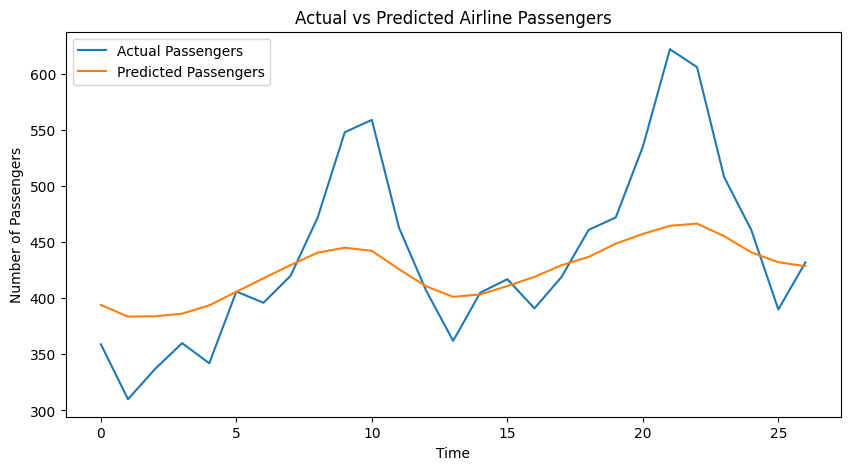

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    y_test_actual,
    label="Actual Passengers"
)

plt.plot(
    test_predictions,
    label="Predicted Passengers"
)

plt.xlabel("Time")
plt.ylabel("Number of Passengers")

plt.title("Actual vs Predicted Airline Passengers")

plt.legend()

plt.show()

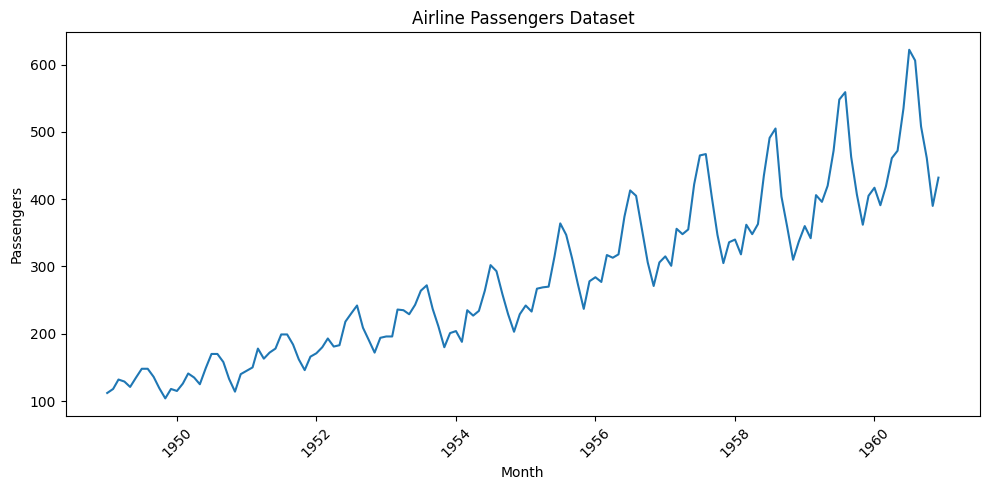

In [ ]:
plt.figure(figsize=(10, 5))

plt.plot(
    df["Month"],
    df["#Passengers"]
)

plt.xlabel("Month")
plt.ylabel("Passengers")

plt.title("Airline Passengers Dataset")

plt.xticks(rotation=45)

plt.tight_layout()

plt.show()